# Phase 2: Probability and Probability Distributions

## 1. Introduction

The objective of this phase is to translate the project's research question into probabilistic terms and examine the probability distributions of selected health-related variables.

This analysis uses data from the NHANES 2021–2023 survey, focusing on adults aged 20 years and older. The unit of observation is an individual participant.

The main focus is the relationship between depressive symptoms, measured using the PHQ-9 questionnaire, and obesity, measured using Body Mass Index (BMI). Additional quantitative health measurements, including waist circumference and blood pressure, are also available for the analysis.

This phase covers empirical probabilities, conditional probabilities, independence, discrete and continuous random variables, binomial and normal distributions, expected value, variance, and covariance.

Because NHANES uses a complex survey sampling design, unweighted sample proportions and weighted population estimates will be distinguished throughout the analysis.

In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyreadstat
from scipy import stats

demo, demo_meta = pyreadstat.read_xport(
    "../data/raw/DEMO_L.xpt",
    encoding="WINDOWS-1252"
)

dpq, dpq_meta = pyreadstat.read_xport(
    "../data/raw/DPQ_L.xpt",
    encoding="WINDOWS-1252"
)

bmx, bmx_meta = pyreadstat.read_xport(
    "../data/raw/BMX_L.xpt",
    encoding="WINDOWS-1252"
)

bpxo, bpxo_meta = pyreadstat.read_xport(
    "../data/raw/BPXO_L.xpt",
    encoding="WINDOWS-1252"
)

In [12]:
# Restrict DEMO to adults aged 20 and above
demo_adults = demo[demo["RIDAGEYR"] >= 20].copy()

# Merge datasets using participant ID (SEQN)
analysis_data = (
    demo_adults
    .merge(dpq, on="SEQN", how="inner", validate="one_to_one")
    .merge(bmx, on="SEQN", how="inner", validate="one_to_one")
    .merge(bpxo, on="SEQN", how="inner", validate="one_to_one")
)

print("Merged dataset shape:", analysis_data.shape)
print("Unique participants:", analysis_data["SEQN"].nunique())

Merged dataset shape: (6064, 69)
Unique participants: 6064


In [13]:
# Variables needed for Phase 2
phq_items = [
    "DPQ010", "DPQ020", "DPQ030",
    "DPQ040", "DPQ050", "DPQ060",
    "DPQ070", "DPQ080", "DPQ090"
]

systolic_items = ["BPXOSY1", "BPXOSY2", "BPXOSY3"]
diastolic_items = ["BPXODI1", "BPXODI2", "BPXODI3"]

selected_columns = [
    "SEQN",
    "RIDAGEYR",
    "RIAGENDR",
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU",
    "BMXBMI",
    "BMXWAIST",
    *phq_items,
    *systolic_items,
    *diastolic_items
]

phase2_data = analysis_data[selected_columns].copy()

# Calculate PHQ-9 only when all nine answers are valid
valid_answers = phase2_data[phq_items].where(
    phase2_data[phq_items].isin([0, 1, 2, 3])
)

phase2_data["PHQ9"] = valid_answers.sum(axis=1, min_count=9)

# Calculate average blood pressure from available readings
phase2_data["Mean_Systolic"] = phase2_data[systolic_items].mean(axis=1)
phase2_data["Mean_Diastolic"] = phase2_data[diastolic_items].mean(axis=1)

print("Phase 2 dataset shape:", phase2_data.shape)

Phase 2 dataset shape: (6064, 26)


## 2. Definition of Events and Random Variables

The following events and random variables are defined at the individual participant level.

### 2.1. Events

Let the sample space consist of eligible adult participants in the merged NHANES dataset.

- **Event A — Obesity:** A participant is classified as obese if their BMI is greater than or equal to 30 kg/m².

- **Event B — Moderate-or-higher depressive symptom severity:** A participant belongs to this event if their total PHQ-9 score is greater than or equal to 10.

The PHQ-9 score is calculated only when all nine questionnaire items have valid responses. A score of 10 or higher is used as a screening threshold for moderate-or-higher depressive symptom severity; it does not constitute a clinical diagnosis.

Both events are binary categorical events, with each participant either belonging or not belonging to each event.

### 2.2. Random Variables

- **X — BMI:** The BMI value of a randomly selected eligible participant. This is a quantitative continuous random variable, measured in kg/m².

- **Y — PHQ-9 score:** The total PHQ-9 score of a randomly selected participant with all nine valid questionnaire responses. This is a discrete random variable taking integer values from 0 to 27.

### 2.3. Analysis Population

For calculations involving events A and B jointly, only participants with valid BMI and PHQ-9 values are included. This ensures that marginal, joint, and conditional probabilities are calculated using a consistent denominator.

Missing values are not treated as event occurrences or non-occurrences; participants with missing values in the variables required for a particular calculation are excluded from that calculation.

In [18]:
# Keep participants with valid BMI and PHQ-9
prob_data = phase2_data.dropna(
    subset=["BMXBMI", "PHQ9"]
).copy()

# Define events A and B
prob_data["A_Obesity"] = prob_data["BMXBMI"] >= 30
prob_data["B_PHQ9"] = prob_data["PHQ9"] >= 10

# Marginal probabilities
P_A = prob_data["A_Obesity"].mean()
P_B = prob_data["B_PHQ9"].mean()

# Joint probability
P_AB = (
    prob_data["A_Obesity"] &
    prob_data["B_PHQ9"]
).mean()

# Conditional probabilities
P_B_given_A = P_AB / P_A
P_A_given_B = P_AB / P_B

print("Number of participants:", len(prob_data))
print("P(A) - Obesity:", P_A)
print("P(B) - PHQ-9 >= 10:", P_B)
print("P(A and B):", P_AB)
print("P(B | A):", P_B_given_A)
print("P(A | B):", P_A_given_B)

# Independence check
print("\nIndependence check:")
print("P(A) * P(B):", P_A * P_B)
print("P(A and B):", P_AB)

Number of participants: 5164
P(A) - Obesity: 0.4138264910921766
P(B) - PHQ-9 >= 10: 0.12509682416731216
P(A and B): 0.06022463206816421
P(B | A): 0.14553111839026672
P(A | B): 0.48142414860681115

Independence check:
P(A) * P(B): 0.05176837979193379
P(A and B): 0.06022463206816421


### 2.4. Empirical Marginal, Joint, and Conditional Probabilities

To estimate the probabilities of events A and B, participants with missing BMI or PHQ-9 values are excluded from this calculation.

The empirical marginal probabilities are estimated using the observed relative frequencies of each event:

- P(A): The proportion of participants classified as obese.
- P(B): The proportion of participants with PHQ-9 scores of 10 or higher.

The joint probability P(A ∩ B) is calculated as the proportion of participants who satisfy both conditions simultaneously.

Two conditional probabilities are then calculated:

- P(B | A): The probability of moderate-or-higher depressive symptom severity among participants classified as obese.
- P(A | B): The probability of obesity among participants with moderate-or-higher depressive symptom severity.

Finally, independence is examined by comparing P(A ∩ B) with P(A) × P(B). If these quantities are approximately equal, the observed probabilities are compatible with independence. Otherwise, the difference suggests an association between the two events.

This is a descriptive probabilistic assessment, not a formal statistical test of independence.

In [19]:
# Calculate P(A | B) using Bayes' theorem
P_A_given_B_bayes = (P_B_given_A * P_A) / P_B

print("Direct calculation of P(A | B):", P_A_given_B)
print("Bayes' theorem calculation:", P_A_given_B_bayes)

print(
    "Absolute difference:",
    abs(P_A_given_B - P_A_given_B_bayes)
)

Direct calculation of P(A | B): 0.48142414860681115
Bayes' theorem calculation: 0.48142414860681115
Absolute difference: 0.0


### Bayes' Theorem

Let:

- $A$: A participant is classified as obese (BMI $\geq 30$).
- $B$: A participant has moderate-to-severe depressive symptoms (PHQ-9 $\geq 10$).

Bayes' theorem expresses the conditional probability of obesity given depressive symptoms as:

$$
P(A\mid B)=\frac{P(B\mid A)\times P(A)}{P(B)}
$$

In our analysis, these probabilities have already been estimated from the empirical frequencies. Therefore, Bayes' theorem provides an alternative way to express the conditional probability calculated earlier using the joint probability.

The two approaches should produce the same result, apart from possible minor differences due to numerical rounding. This illustrates how conditional probabilities can be reversed using the joint probability and the marginal probabilities.

All probabilities here are unweighted empirical estimates from the analyzed sample.

In [20]:
# Keep participants with valid BMI and gender
gender_data = phase2_data.dropna(
    subset=["BMXBMI", "RIAGENDR"]
).copy()

# Define obesity event
gender_data["Obesity"] = gender_data["BMXBMI"] >= 30

# Calculate conditional probabilities by gender
gender_probabilities = (
    gender_data
    .groupby("RIAGENDR")["Obesity"]
    .agg(["count", "sum", "mean"])
)

# Add readable group labels
gender_probabilities.index = gender_probabilities.index.map({
    1: "Male",
    2: "Female"
})

gender_probabilities = gender_probabilities.rename(
    columns={
        "count": "Number of participants",
        "sum": "Number of obese participants",
        "mean": "Empirical probability of obesity"
    }
)

print(gender_probabilities)

          Number of participants  Number of obese participants  \
RIAGENDR                                                         
Male                        2680                          1026   
Female                      3290                          1429   

          Empirical probability of obesity  
RIAGENDR                                    
Male                              0.382836  
Female                            0.434347  


### Conditional Probability of Obesity by Sex

To examine whether the empirical probability of obesity differs between males and females, participants were divided into two groups according to the NHANES variable `RIAGENDR`. Obesity was defined as having a BMI greater than or equal to 30:

$$
A = \{\text{BMI} \geq 30\}
$$

The conditional probability of obesity was calculated separately for each group:

$$
P(A \mid \text{Male}) =
\frac{\text{Number of obese male participants}}
{\text{Total number of male participants}}
$$

$$
P(A \mid \text{Female}) =
\frac{\text{Number of obese female participants}}
{\text{Total number of female participants}}
$$

The results are presented below:

| Sex | Number of participants | Number of obese participants | Empirical probability of obesity |
|---|---:|---:|---:|
| Male | 2,680 | 1,026 | 0.3828 (38.28%) |
| Female | 3,290 | 1,429 | 0.4343 (43.43%) |

The empirical probability of obesity was approximately **38.28% among males** and **43.43% among females**. Thus, within this sample, the observed probability of obesity was about **5.15 percentage points higher among females**.

This illustrates how conditioning on a subgroup changes the probability being examined. Instead of considering the overall probability of obesity among all participants, we calculate the relative frequency of obesity within each sex group.

These results describe an association in the analyzed sample. They do not establish that sex causes differences in obesity, nor do they indicate whether the observed difference is statistically significant. Furthermore, these are unweighted empirical probabilities; therefore, they should not automatically be interpreted as population-level estimates for all adults in the United States.

### Assessing the Suitability of a Binomial Model (Common Requirement 5)

For this analysis, we define a binary event based on obesity status: a participant is classified as obese if their BMI is at least 30. We consider a hypothetical sample of 100 participants and define \(X\) as the number of obese participants in that sample.

A binomial model can be appropriate for this count if the following assumptions hold:

1. **Fixed number of trials:** The number of participants must be fixed. In our setting, each hypothetical sample contains exactly 100 participants. This condition is satisfied.

2. **Two possible outcomes:** Each participant must have one of two possible outcomes: obese (BMI ≥ 30) or not obese (BMI < 30). This condition is satisfied by our event definition.

3. **Constant probability of success:** Each participant should have the same probability \(p\) of being classified as obese. We estimate this probability empirically from the available NHANES observations. However, obesity prevalence may vary across characteristics such as age and sex. Therefore, assuming one common probability for all participants is a simplifying approximation.

4. **Independence of trials:** The obesity status of one participant should not affect the obesity status of another participant. In practice, participants may share demographic, environmental, or other risk factors. Furthermore, NHANES uses a complex survey design involving stratification and clustering, so complete independence cannot automatically be assumed.

**Conclusion:** The fixed sample size and binary-outcome assumptions are satisfied by our definition. However, constant success probability and independence are less certain in the real NHANES population. Thus, a binomial model may provide a useful approximation for the number of obese participants in a sample of fixed size, but its assumptions should be interpreted cautiously in the context of the NHANES sampling design.

## 3. Discrete Random Variable and the Binomial Model

To examine the binomial model, obesity is used as the binary event of interest. A participant is classified as obese if their BMI is at least 30 kg/m².

Let \(X\) represent the number of obese participants in a subsample of 100 adults. Using the empirical obesity proportion from the analyzed dataset as an estimate of the probability of success, the proposed model is:

$$
X\sim Binomial(n=100,p=\hat p)
$$

where $$ \hat p\ $$ is the observed proportion of obese participants.

To examine this model empirically, the available participants are randomly rearranged and divided into 50 non-overlapping groups of 100 participants. The number of obese participants is counted in each group. The observed distribution of these counts is then compared with the theoretical binomial distribution.

Because the groups are formed by partitioning a finite dataset, their counts are not independent of one another. Furthermore, NHANES uses a complex survey sampling design. Therefore, the binomial distribution is treated as an approximation rather than an exact representation of the survey sampling process.

Number of groups: 50
Participants per group: 100
Estimated obesity probability: 0.4112227805695142

Observed count statistics:
Mean: 41.28
Variance: 26.899591836734697

Theoretical binomial statistics:
Mean: 41.12227805695142
Variance: 24.211860531019138


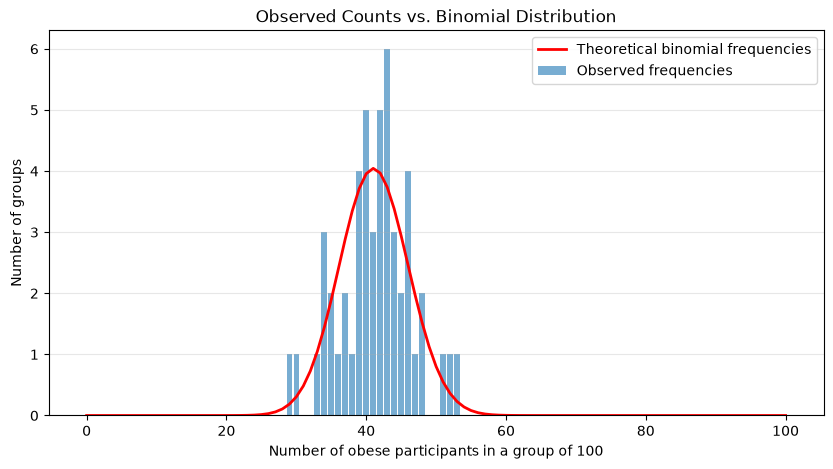

In [22]:
n = 100
number_of_groups = 50

rng = np.random.default_rng(42)

obesity_values = obesity_data["A_Obesity"].to_numpy()
shuffled_obesity = rng.permutation(obesity_values)

subsample_values = shuffled_obesity[:n * number_of_groups]
subsamples = subsample_values.reshape(number_of_groups, n)

observed_counts = subsamples.sum(axis=1)

k = np.arange(n + 1)

theoretical_probabilities = stats.binom.pmf(
    k, n, P_A_binomial
)

expected_frequencies = theoretical_probabilities * number_of_groups

observed_frequencies = np.bincount(
    observed_counts, minlength=n + 1
)

print("Number of groups:", number_of_groups)
print("Participants per group:", n)
print("Estimated obesity probability:", P_A_binomial)

print("\nObserved count statistics:")
print("Mean:", observed_counts.mean())
print("Variance:", observed_counts.var(ddof=1))

print("\nTheoretical binomial statistics:")
print("Mean:", n * P_A_binomial)
print("Variance:", n * P_A_binomial * (1 - P_A_binomial))

plt.figure(figsize=(10, 5))

plt.bar(
    k,
    observed_frequencies,
    alpha=0.6,
    label="Observed frequencies"
)

plt.plot(
    k,
    expected_frequencies,
    color="red",
    linewidth=2,
    label="Theoretical binomial frequencies"
)

plt.xlabel("Number of obese participants in a group of 100")
plt.ylabel("Number of groups")
plt.title("Observed Counts vs. Binomial Distribution")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

### 4. Empirical Comparison of Subsample Counts with a Binomial Model

To examine how well a binomial distribution approximates the count of individuals with obesity, we defined obesity as having a BMI greater than or equal to 30.

The analysis included all 5,970 participants with valid BMI measurements. Among them, 2,455 were classified as having obesity, giving an empirical probability of:

$$
p = \frac{2455}{5970} \approx 0.4112
$$

We randomly shuffled the observations and divided the first 5,000 participants into 50 equal-sized groups, each containing 100 individuals. For each group, we counted the number of participants classified as having obesity.

Under a binomial model with \(n=100\) and \(p=0.4112\), the theoretical mean and variance are:

$$
E(X)=np=100(0.4112)\approx 41.12
$$

$$
Var(X)=np(1-p)
=100(0.4112)(1-0.4112)
\approx 24.21
$$

The empirical results from the 50 groups were:

- Observed mean count: **41.28**
- Observed variance: **26.90**

The observed mean is very close to the theoretical binomial mean. The observed variance is approximately 11% higher than the theoretical variance.

The histogram and theoretical binomial curve show a broadly similar distribution, with both concentrated around 41 obese individuals per group. However, the observed frequencies do not match the theoretical frequencies exactly. Some counts occur more frequently and others less frequently than predicted by the model.

This discrepancy may partly reflect random variation, particularly because only 50 groups were examined. Furthermore, the groups were formed by partitioning a finite dataset without replacement. Consequently, the count within an individual group is more precisely described by a hypergeometric distribution, although a binomial approximation is reasonable because each group represents only a small fraction of the full dataset. The group counts are also not fully independent because they were formed from the same finite pool of participants.

Overall, the binomial distribution provides a reasonable approximation for describing the number of participants with obesity in groups of 100, but the observed results should not be interpreted as evidence of an exact binomial fit.

Number of valid observations: 5863
Mean: 122.92967195406221
Median: 120.33333333333333
Standard deviation: 18.080906982998048
Skewness: 0.9370485388266767


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13328\1468316646.py:37: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(systolic_values, vert=False)


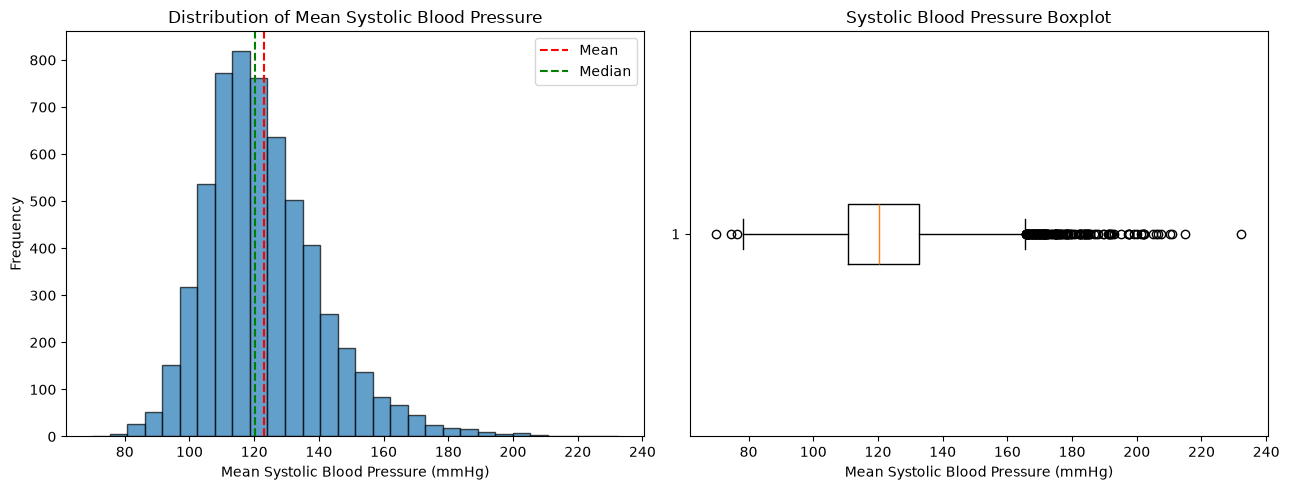

In [23]:
systolic_values = phase2_data["Mean_Systolic"].dropna()

print("Number of valid observations:", len(systolic_values))
print("Mean:", systolic_values.mean())
print("Median:", systolic_values.median())
print("Standard deviation:", systolic_values.std())
print("Skewness:", stats.skew(systolic_values, bias=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    systolic_values,
    bins=30,
    edgecolor="black",
    alpha=0.7
)

axes[0].axvline(
    systolic_values.mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    systolic_values.median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("Distribution of Mean Systolic Blood Pressure")
axes[0].set_xlabel("Mean Systolic Blood Pressure (mmHg)")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].boxplot(systolic_values, vert=False)

axes[1].set_title("Systolic Blood Pressure Boxplot")
axes[1].set_xlabel("Mean Systolic Blood Pressure (mmHg)")

plt.tight_layout()
plt.show()

In [26]:
q1 = systolic_values.quantile(0.25)
q3 = systolic_values.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = systolic_values[
    (systolic_values < lower_bound) |
    (systolic_values > upper_bound)
]

print("Variance:", systolic_values.var(ddof=1))
print("Minimum:", systolic_values.min())
print("Q1:", q1)
print("Median:", systolic_values.median())
print("Q3:", q3)
print("Maximum:", systolic_values.max())
print("IQR:", iqr)
print("Lower outlier boundary:", lower_bound)
print("Upper outlier boundary:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("Percentage of potential outliers:", len(outliers) / len(systolic_values) * 100)

Variance: 326.91919732782753
Minimum: 70.0
Q1: 110.66666666666667
Median: 120.33333333333333
Q3: 132.66666666666666
Maximum: 232.33333333333334
IQR: 21.999999999999986
Lower outlier boundary: 77.66666666666669
Upper outlier boundary: 165.66666666666663
Number of potential outliers: 154
Percentage of potential outliers: 2.6266416510318953


## 5. Continuous Variable and Normal Distribution

### Distribution of Systolic Blood Pressure

Mean systolic blood pressure was selected as the continuous health measurement for this analysis. For each participant, the available systolic blood pressure readings were averaged to obtain a single value.

A total of 5,863 participants had at least one valid systolic blood pressure measurement.

The distribution was examined using a histogram and a boxplot. The descriptive statistics were:

| Statistic | Value |
|---|---:|
| Mean | 122.93 mmHg |
| Median | 120.33 mmHg |
| Standard deviation | 18.08 mmHg |
| Skewness | 0.937 |
| Minimum | 70.00 mmHg |
| Maximum | 232.33 mmHg |

The mean is higher than the median, and the positive skewness indicates that the distribution is asymmetric, with a longer right tail. Therefore, the distribution does not appear to be perfectly symmetric or normally distributed.

The boxplot was also used to identify potential outliers. Using the 1.5 × IQR rule:

- First quartile (Q1): 110.67 mmHg
- Third quartile (Q3): 132.67 mmHg
- Interquartile range (IQR): 22.00 mmHg
- Lower boundary: 77.67 mmHg
- Upper boundary: 165.67 mmHg

A total of 154 observations (approximately 2.63% of valid measurements) were identified as potential outliers.

These observations are not necessarily measurement errors. They are values that lie relatively far from the central part of the distribution.

Overall, the positive skewness and the presence of potential outliers suggest that a normal distribution may not be an ideal description of the raw systolic blood pressure measurements. The histogram and boxplot provide visual evidence supporting this assessment. A normal approximation should therefore be treated with caution rather than assumed automatically.

## 6. Expected Value and Variance

For the selected variable, mean systolic blood pressure, the empirical expected value is estimated by the sample mean:

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n}x_i
$$

The estimated mean is:

$$
\bar{x} \approx 122.93 \text{ mmHg}
$$

This means that the average systolic blood pressure among participants with valid measurements was approximately 122.93 mmHg.

The sample variance is calculated as:

$$
s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2
$$

The resulting variance is:

$$
s^2 \approx 326.92 \text{ mmHg}^2
$$

The corresponding standard deviation is:

$$
s \approx 18.08 \text{ mmHg}
$$

The variance describes the spread of systolic blood pressure measurements around their mean. A larger variance indicates greater dispersion among participants.

These statistics describe the observed sample and should not be interpreted as population estimates that account for the full NHANES complex survey design.